# ElliGAT — Full Pipeline (Colab)

Runs the **entire** pipeline: all 5 seeds, full epochs, ElliGAT + EvolveGCN + BaselineGNN + ROLAND + TGN + tabular baselines + MetaEnsemble, MC-dropout, PLP, GNNExplainer, plots. No smoke test.

1. Runtime → Change runtime type → **T4 GPU**
2. Run all cells top to bottom (Runtime → Run all). Keep the tab open; expect ~1–1.5 h.
3. Outputs are written **directly to Google Drive**, so they survive a disconnect.

## 1. Config

In [1]:
SEEDS         = "42,123,2024,17,99"
EPOCHS        = 300
HIDDEN_DIM    = 128            # 256 runs out of memory on a 15 GB T4 (contrastive loss over 468k edges). Auto-halves again on OOM.
LOSS_NAME     = "asymmetric"   # "asymmetric" (current default) | "focal" (README-verified numbers)
EDGE_ENCODING = "sinusoidal"   # "sinusoidal" (current default)   | "mlp"   (README-verified numbers)
METHODS       = "all"
EXPLAIN_NODES, EXPLAIN_EPOCHS = 10, 100   # GNNExplainer is slow on the full graph; raise if you want more

GITHUB_URL    = "https://github.com/ria0304/Bitcoin-Transaction-Fraud-Detection-"
DATA_SOURCE   = "pyg"          # "pyg" (no login) | "upload" (3 CSVs) | "drive" | "kaggle"
DRIVE_DATA_DIR = "/content/drive/MyDrive/elligat_data"   # only for DATA_SOURCE == "drive"

## 2. GPU check + mount Drive

In [2]:
import torch, os, time
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then re-run."
print(torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount("/content/drive")
OUT_DIR = f"/content/drive/MyDrive/elligat_full_{time.strftime('%Y%m%d_%H%M')}"
os.makedirs(OUT_DIR, exist_ok=True)
print("Outputs ->", OUT_DIR)

torch 2.11.0+cu130 | CUDA: True
Tesla T4
Mounted at /content/drive
Outputs -> /content/drive/MyDrive/elligat_full_20261021_1425


## 3. Clone the repo

In [3]:
%cd /content
!rm -rf /content/elligat
!git clone {GITHUB_URL} /content/elligat
%cd /content/elligat

/content
Cloning into '/content/elligat'...
remote: Enumerating objects: 185, done.
remote: Counting objects: 100% (156/156), done.
remote: Compressing objects: 100% (118/118), done.
remote: Total 185 (delta 70), reused 53 (delta 23), pack-reused 29 (from 1)
Receiving objects: 100% (185/185), 678.66 KiB | 1.60 MiB/s, done.
Resolving deltas: 100% (74/74), done.
/content/elligat


## 4. Install dependencies + apply two bug fixes
The repo currently has two bugs that surfaced in the smoke test (GNNExplainer rejects `edge_attr`; the results plot crashes on CUDA tensors). They are patched here after cloning; once you fix them in the repo this cell becomes a harmless no-op.

In [4]:
!pip install -q torch_geometric xgboost lightgbm python-dotenv kagglehub kaggle
import torch_geometric; print("torch_geometric", torch_geometric.__version__)

import re
# ---- Fix 1: GNNExplainer passes edge_attr as a kwarg, but ElliGAT.forward(data) takes a Data object ----
p = "src/explain.py"; s = open(p).read()
if "_ExplainWrap" not in s:
    wrapper = '''
class _ExplainWrap(torch.nn.Module):
    """Adapter: Explainer calls model(x, edge_index, **kw); ElliGAT expects model(data)."""
    def __init__(self, m):
        super().__init__()
        self.m = m
    def forward(self, x, edge_index, edge_attr=None):
        return self.m(Data(x=x, edge_index=edge_index, edge_attr=edge_attr))

'''
    marker = "def explain_fraud_nodes("
    assert marker in s
    s = s.replace(marker, wrapper + marker, 1)
    old = "    explainer = Explainer(\n        model=model,"
    assert old in s
    s = s.replace(old, "    explainer = Explainer(\n        model=_ExplainWrap(model),", 1)
    if "from torch_geometric.data import Data" not in s:
        s = "from torch_geometric.data import Data\n" + s
    open(p, "w").write(s)

# ---- Fix 2: plotting crashes on CUDA tensors -> convert every input to CPU numpy first ----
p = "src/visualize.py"; s = open(p).read()
if "_save_results_figure_impl" not in s:
    assert "def save_results_figure(" in s
    s = s.replace("def save_results_figure(", "def _save_results_figure_impl(", 1)
    s += '''


def _cpuify(o):
    import torch
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().numpy()
    if isinstance(o, dict):
        return {k: _cpuify(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return type(o)(_cpuify(v) for v in o)
    return o


def save_results_figure(*args, **kwargs):
    return _save_results_figure_impl(*_cpuify(args), **_cpuify(kwargs))
'''
    open(p, "w").write(s)

import py_compile; py_compile.compile("src/explain.py", doraise=True); py_compile.compile("src/visualize.py", doraise=True)
print("Patches applied and compile OK")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 80.5 MB/s eta 0:00:00
torch_geometric 2.8.1
Patches applied and compile OK


## 5. Dataset
`pyg` downloads the same three Elliptic CSVs from PyTorch Geometric's host (no account or keys). Alternatives: `upload`, `drive`, `kaggle`.

In [5]:
import os, glob, shutil
DATA_DIR = "/content/data/elliptic"
os.makedirs(DATA_DIR, exist_ok=True)

if DATA_SOURCE == "pyg":
    for n in ["features", "edgelist", "classes"]:
        !wget -q -P {DATA_DIR} https://data.pyg.org/datasets/elliptic/elliptic_txs_{n}.csv.zip
    !cd {DATA_DIR} && unzip -o -q "*.zip"
elif DATA_SOURCE == "upload":
    from google.colab import files
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
elif DATA_SOURCE == "drive":
    for f in glob.glob(os.path.join(DRIVE_DATA_DIR, "**", "elliptic_txs_*.csv"), recursive=True):
        shutil.copy(f, DATA_DIR)
elif DATA_SOURCE == "kaggle":
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")
    !kaggle datasets download -d ellipticco/elliptic-data-set -p {DATA_DIR} --unzip

feat = glob.glob(os.path.join(DATA_DIR, "**", "elliptic_txs_features.csv"), recursive=True)
assert feat, "elliptic_txs_features.csv not found"
DATA_DIR = os.path.dirname(feat[0])
for n in ["features", "classes", "edgelist"]:
    assert os.path.exists(f"{DATA_DIR}/elliptic_txs_{n}.csv"), f"missing elliptic_txs_{n}.csv"
print("Dataset OK:", DATA_DIR)


3 archives were successfully processed.
Dataset OK: /content/data/elliptic


## 6. Run the full pipeline (~1–1.5 h)

In [6]:
os.environ.update(dict(
    PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True",
    BITCOIN_DATA_PATH=DATA_DIR, ELLIPTIC_CACHE_PATH=DATA_DIR,
    OUTPUT_DIR=OUT_DIR,
    SEEDS=SEEDS, EPOCHS=str(EPOCHS), HIDDEN_DIM=str(HIDDEN_DIM),
    LOSS_NAME=LOSS_NAME, EDGE_ENCODING=EDGE_ENCODING, METHODS=METHODS,
    EXPLAIN_NODES=str(EXPLAIN_NODES), EXPLAIN_EPOCHS=str(EXPLAIN_EPOCHS),
))
print({k: os.environ[k] for k in ["SEEDS","EPOCHS","HIDDEN_DIM","LOSS_NAME","EDGE_ENCODING","METHODS","OUTPUT_DIR"]})

{'SEEDS': '42,123,2024,17,99', 'EPOCHS': '300', 'HIDDEN_DIM': '128', 'LOSS_NAME': 'asymmetric', 'EDGE_ENCODING': 'sinusoidal', 'METHODS': 'all', 'OUTPUT_DIR': '/content/drive/MyDrive/elligat_full_20261021_1425'}


In [7]:
import subprocess, gc, torch

def run_pipeline(hidden):
    os.environ["HIDDEN_DIM"] = str(hidden)
    print(f"\n>>> Running with HIDDEN_DIM={hidden}\n")
    log = f"{OUT_DIR}/run_log_final.txt"
    out = []
    with open(log, "a") as lf:
        p = subprocess.Popen(["python", "-u", "main.py"], stdout=subprocess.PIPE,
                             stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            print(line, end=""); lf.write(line); out.append(line)
        p.wait()
    return p.returncode, "".join(out[-200:])

hidden = int(HIDDEN_DIM)
while True:
    rc, tail = run_pipeline(hidden)
    if rc == 0:
        break
    if "OutOfMemoryError" in tail and hidden > 32:
        hidden //= 2
        gc.collect(); torch.cuda.empty_cache()
        print(f"\n!! CUDA OOM - retrying with HIDDEN_DIM={hidden}")
        continue
    raise RuntimeError(f"main.py failed (exit code {rc}); see the traceback above.")



>>> Running with HIDDEN_DIM=128

2026-10-21 14:26:26 | INFO    | Novelty: ElliGAT-ASL loss=asymmetric gamma_pos=0.0 gamma_neg=4.0

  Bitcoin Fraud Detection — ElliGAT
  Device : cuda
  Output : /content/drive/MyDrive/elligat_full_20261021_1425

Step 1: Loading Elliptic Bitcoin dataset …
  [check] found dataset at: /content/data/elliptic
  Path: /content/data/elliptic
  Loaded edges: 234355 directed → 468710 undirected
  [Elliptic] 203,769 total | 46,564 labelled | Fraud: 0.0976

Step 2: Engineering velocity features …

Step 3: Chronological train/val/test split (70/15/15) …
  Train: 32,594  Val: 6,984  Test: 6,986
  Tabular features: 172 (7 velocity + 165 raw)
  Class balance — Fraud: 3753 (11.514%)

Step 4: Building Bitcoin transaction graph …
  Nodes: 203,769  Edges: 468,710  Features/node: 172
  Methods to run: ['ElliGAT', 'EvolveGCN', 'BaselineGNN', 'ROLAND', 'TGN', 'Tabular', 'Meta']

Step 5: Multi-seed experiments (5 seeds) …


───────────────────────────────────────────────────

## 7. Results (from THIS run only)

,Model,ROC-AUC,F1,MCC,Precision,Recall
0,ElliGAT,0.7635 ± 0.0368,0.1418 ± 0.0000,0.0000 ± 0.0000,0.0763 ± 0.0000,1.0000 ± 0.0000
1,EvolveGCN,0.5823 ± 0.0649,0.1437 ± 0.0038,0.0083 ± 0.0165,0.0780 ± 0.0034,0.9377 ± 0.1246
2,BaselineGNN,0.6676 ± 0.0321,0.1433 ± 0.0031,0.0089 ± 0.0178,0.0801 ± 0.0076,0.8694 ± 0.2612
3,ROLAND,0.9003 ± 0.0144,0.1481 ± 0.0073,0.0491 ± 0.0402,0.0800 ± 0.0043,1.0000 ± 0.0000
4,TGN,0.8651 ± 0.0103,0.1513 ± 0.0110,0.0649 ± 0.0428,0.0819 ± 0.0065,1.0000 ± 0.0000
5,MLP,0.9673 ± 0.0068,0.8206 ± 0.0047,0.8167 ± 0.0062,0.9489 ± 0.0240,0.7235 ± 0.0132
6,XGBoost,0.9916 ± 0.0003,0.8646 ± 0.0018,0.8581 ± 0.0013,0.9450 ± 0.0093,0.7970 ± 0.0093
7,LightGBM,0.9917 ± 0.0001,0.8770 ± 0.0039,0.8715 ± 0.0049,0.9598 ± 0.0150,0.8075 ± 0.0076
8,RandomForest,0.9894 ± 0.0007,0.8441 ± 0.0021,0.8405 ± 0.0031,0.9640 ± 0.0090,0.7508 ± 0.0022
9,MetaEnsemble,0.9908 ± 0.0008,0.8684 ± 0.0016,0.8627 ± 0.0015,0.9550 ± 0.0045,0.7962 ± 0.0047


config: {'loss': 'asymmetric', 'seeds': [42, 123, 2024, 17, 99], 'epochs': 300, 'methods': ['ElliGAT', 'EvolveGCN', 'BaselineGNN', 'ROLAND', 'TGN', 'Tabular', 'Meta'], 'novel': ['FAGA', 'AUGT', 'PLP', 'GNNExplainer']}
/content/drive/MyDrive/elligat_full_20261021_1425/results.png


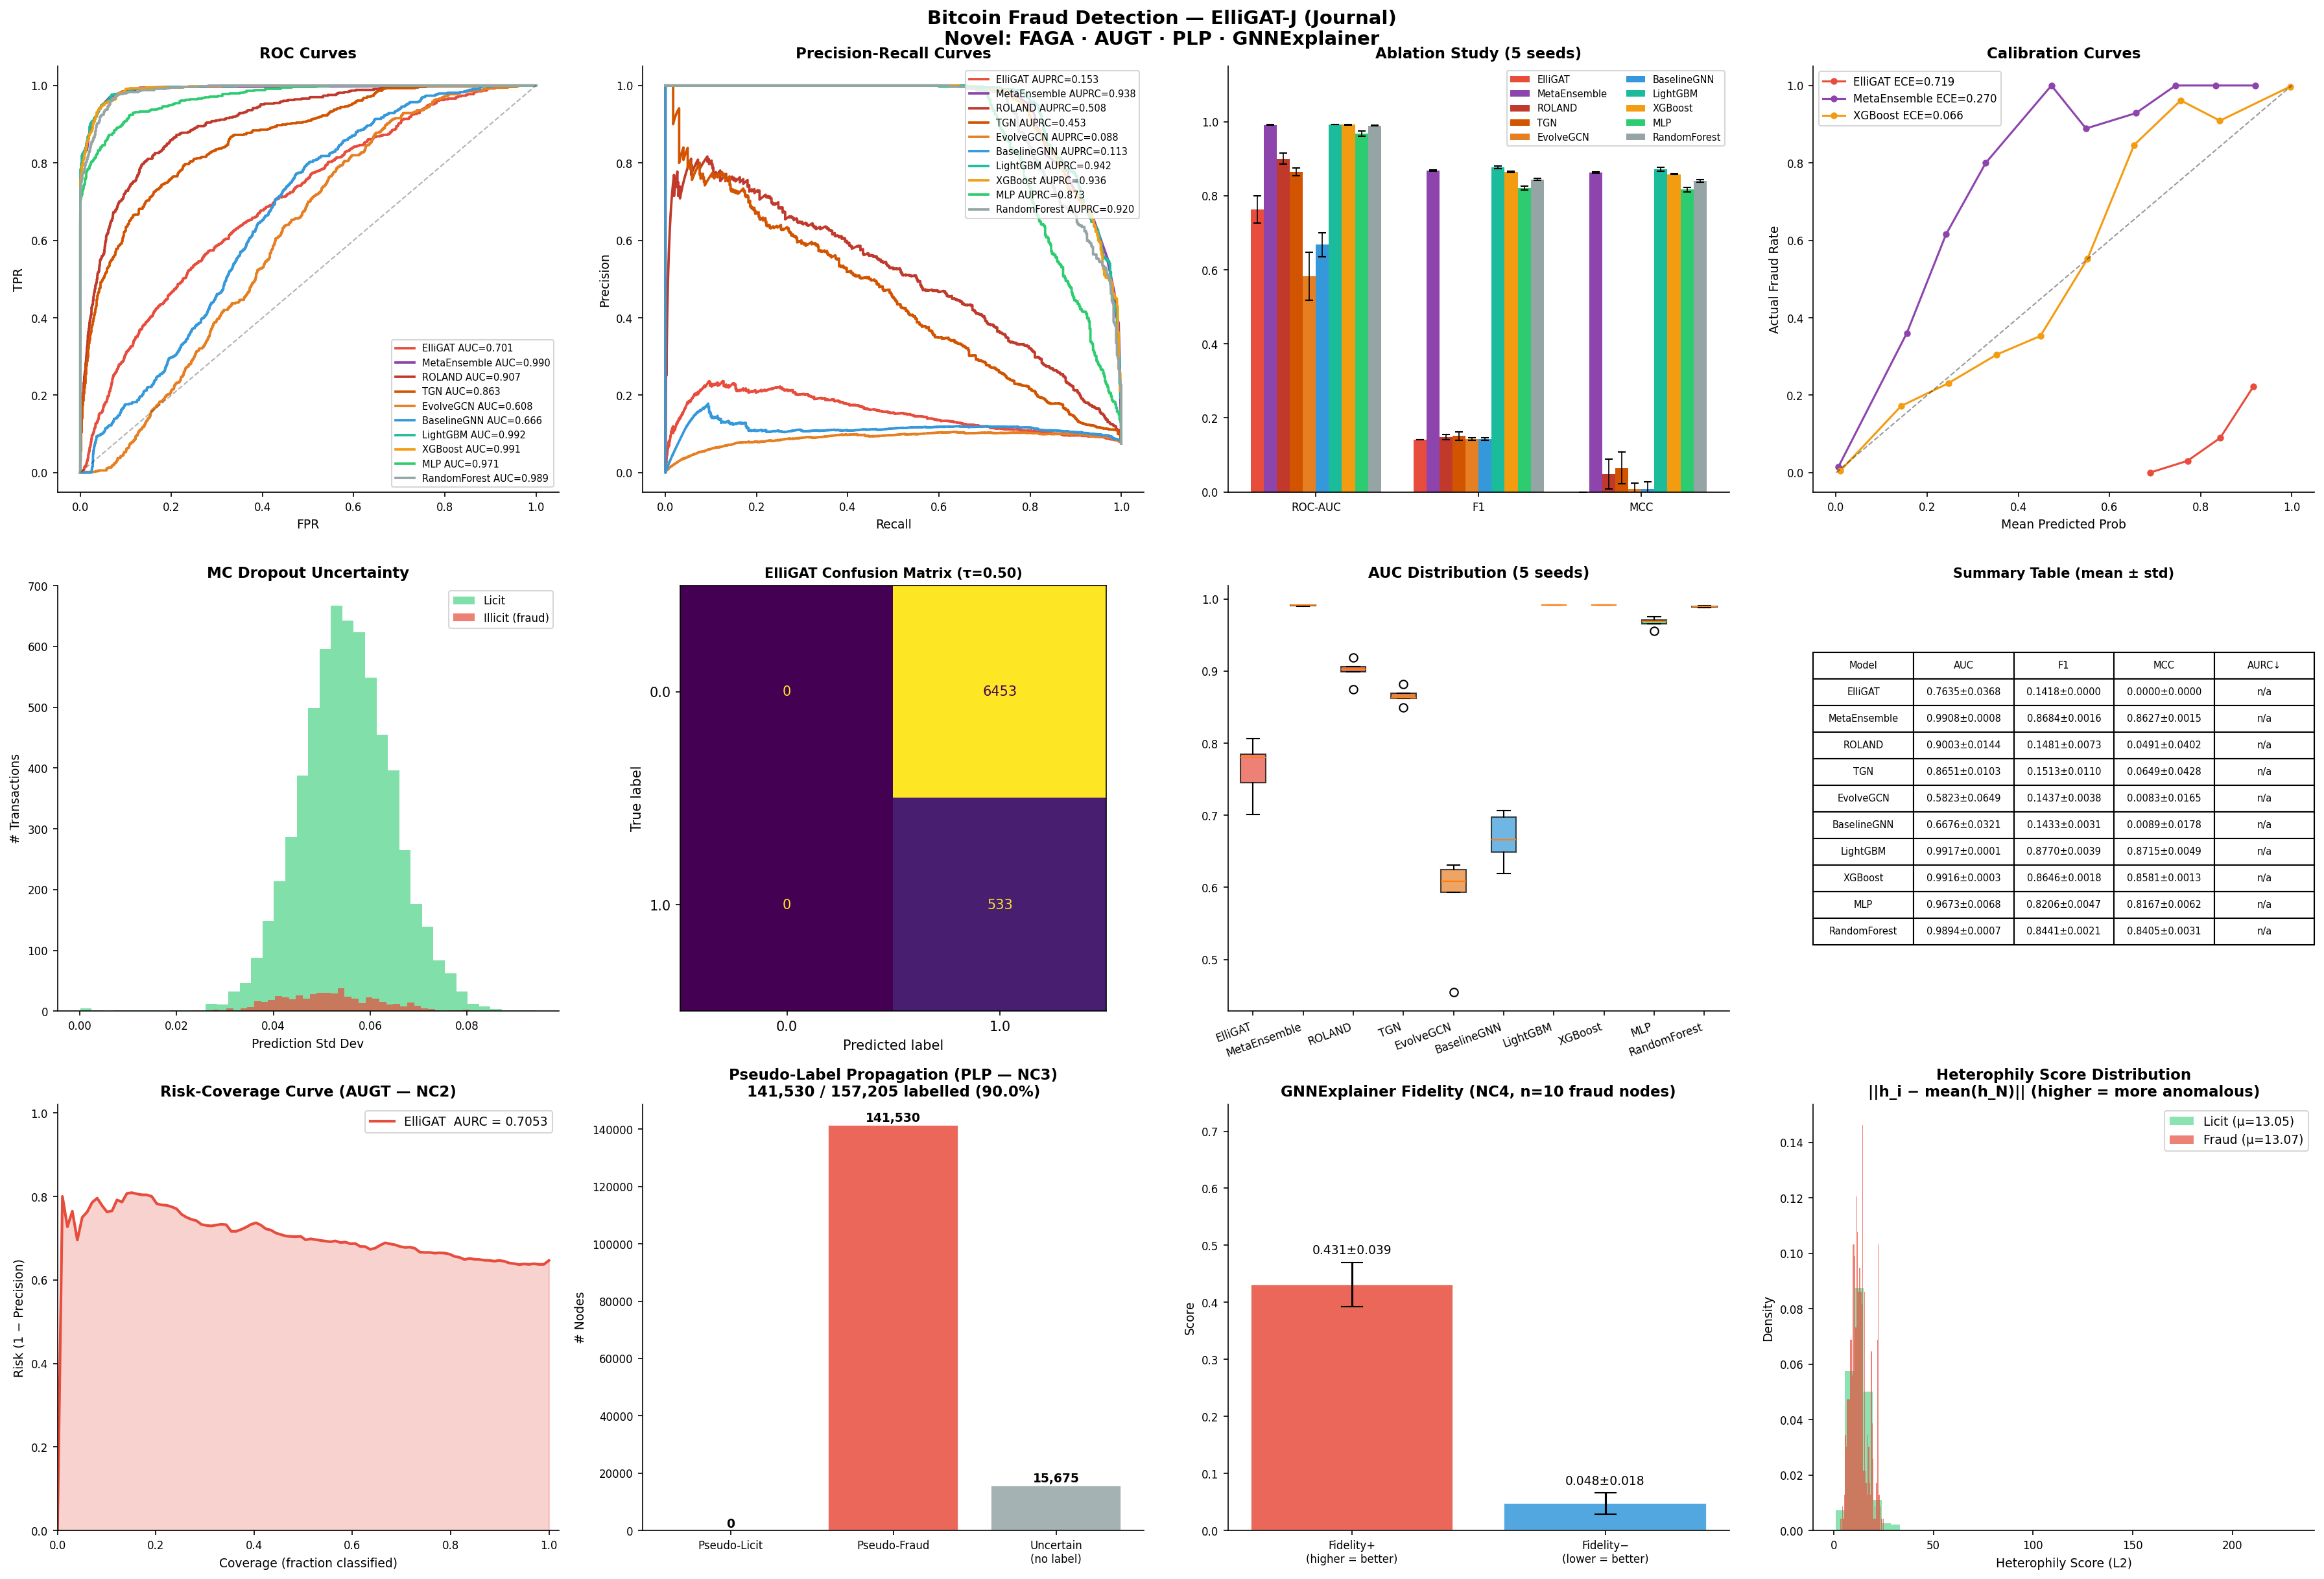

['run_log_final.txt', 'run_log.txt', 'elligat_probs_seed42.npz', 'elligat_probs_seed123.npz', 'elligat_probs_seed2024.npz', 'elligat_probs_seed17.npz', 'elligat_probs_seed99.npz', 'metrics.json', 'best_model.pt', 'results.png', 'run_summary.txt']


In [8]:
import json, glob, os
import pandas as pd
from IPython.display import Image, display

mp = f"{OUT_DIR}/metrics.json"
assert os.path.exists(mp), "metrics.json missing - the pipeline did not finish; check the traceback in the run cell above."
m = json.load(open(mp))
rows = []
for name, v in m.items():
    if name.startswith("_") or not isinstance(v, dict) or "ROC-AUC" not in v: continue
    rows.append({"Model": name,
                 **{k: f"{v[k]['mean']:.4f} ± {v[k]['std']:.4f}" for k in ["ROC-AUC","F1","MCC","Precision","Recall"] if k in v}})
display(pd.DataFrame(rows))
print("config:", m.get("_config"))

for p in sorted(glob.glob(f"{OUT_DIR}/*.png")):
    print(p); display(Image(p))
if not glob.glob(f"{OUT_DIR}/*.png"):
    print("No PNGs were written - check the 'Plot skipped' line in the log above.")
print(os.listdir(OUT_DIR))

## 8. Download a zip (optional — everything is already in Drive)

In [9]:
import shutil
from google.colab import files
shutil.make_archive("/content/elligat_full_outputs", "zip", OUT_DIR)
files.download("/content/elligat_full_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>